In [53]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import pathlib as path 
import plotly.express as px
import seaborn as sns

In [54]:
root_dir = path.Path('homerton_data')
data_method_dir = root_dir / 'web_data'

extras = pd.read_csv('other_data.csv')
data = pd.read_parquet(data_method_dir / 'slopes.parquet')

In [55]:
data.set_index('reading_id', inplace=True)
data


,ground,temp,rh,lat,lon,notes,tod,dCO2_ppm_dt_hr,dCO2_ppm_dt_hr_std,slope_r2,...,sa_err,day,UTC start,dCO2_mol_dt_hr,dCO2_mol_dt_hr_std,dCO2_g_dt_hr,dCO2_g_dt_hr_std,dCO2_g_dt_hr_m2,dCO2_g_dt_hr_m2_std,log_dCO2_g_dt_hr_m2
reading_id,,,,,,,,,,,,,,,,,,,,,
0,concrete,11.1,57.0,52.18509,0.13425,None,morning,-7.896936,7.302932,0.143133,...,0.004,Wednesday,2026-11-18 08:44:30+00:00,-1.303465e-06,0.000001,-0.000057,0.000053,-0.001171,0.001083,NaN
1,concrete,11.1,62.0,52.18512,0.13423,1x car passed,morning,1.405297,10.447183,0.002578,...,0.004,Wednesday,2026-11-18 08:57:34+00:00,2.319577e-07,0.000002,0.000010,0.000076,0.000208,0.001549,-8.476359
2,concrete,9.9,67.0,52.18508,0.13399,None,morning,-32.493036,16.799521,0.348291,...,0.004,Wednesday,2026-11-18 09:07:34+00:00,-5.386025e-06,0.000003,-0.000237,0.000123,-0.004838,0.002501,NaN
3,grass,9.6,82.0,52.18488,0.13327,None,morning,674.395877,78.595859,0.913179,...,0.004,Wednesday,2026-11-18 09:20:34+00:00,1.119060e-04,0.000013,0.004925,0.000574,0.100510,0.011714,-2.297499
4,grass,9.5,77.0,52.18456,0.13308,None,morning,138.774726,53.646755,0.488740,...,0.004,Wednesday,2026-11-18 09:33:34+00:00,2.303576e-05,0.000009,0.001014,0.000392,0.020690,0.007998,-3.878111
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
76,canopy,4.1,80.0,52.18460,0.13171,None,evening,3431.337047,105.794925,0.993390,...,0.004,Friday,2026-11-20 19:08:31+00:00,5.806749e-04,0.000018,0.025556,0.000788,0.521541,0.016080,-0.650968
77,canopy,4.1,83.0,52.18460,0.13171,None,evening,3079.403272,178.388902,0.977048,...,0.004,Friday,2026-11-20 19:23:32+00:00,5.211182e-04,0.000030,0.022934,0.001329,0.468049,0.027114,-0.759182
78,concrete,3.2,81.0,52.18510,0.13412,None,evening,59.781972,27.342567,0.405791,...,0.004,Friday,2026-11-20 19:37:31+00:00,1.014967e-05,0.000005,0.000447,0.000204,0.009116,0.004169,-4.697717


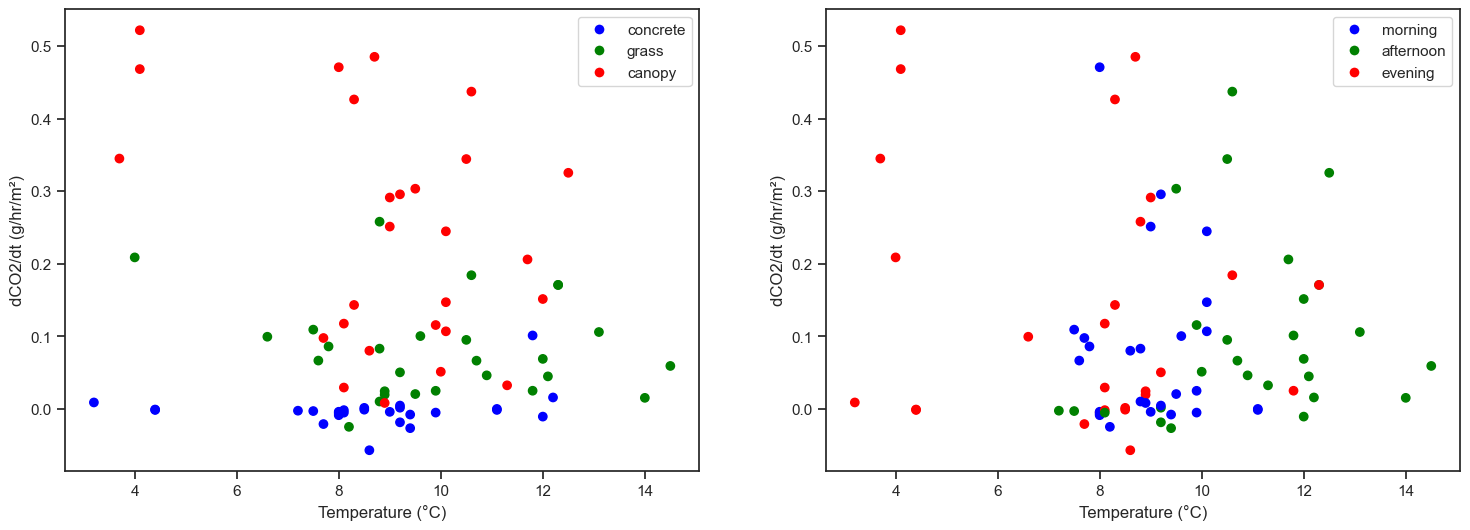

In [56]:

ground_dict = { 'concrete':'blue', 'grass':'green', 'canopy':'red'}
tod_dict = { 'morning':'blue', 'afternoon':'green', 'evening':'red'}


plt.figure(figsize=(18,6))

plt.subplot(1, 2, 1)
plt.scatter( data['temp'], data['dCO2_g_dt_hr_m2'], color=[ ground_dict[i] for i in data['ground'] ])
plt.xlabel('Temperature (°C)')
plt.ylabel('dCO2/dt (g/hr/m²)')
plt.legend(handles=[plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=ground_dict[key], markersize=8, label=key) for key in ground_dict])

plt.subplot(1, 2, 2)
plt.scatter( data['temp'], data['dCO2_g_dt_hr_m2'], color=[ tod_dict[i] for i in data['tod'] ])
plt.xlabel('Temperature (°C)')
plt.ylabel('dCO2/dt (g/hr/m²)')
plt.legend(handles=[plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=tod_dict[key], markersize=8, label=key) for key in tod_dict])

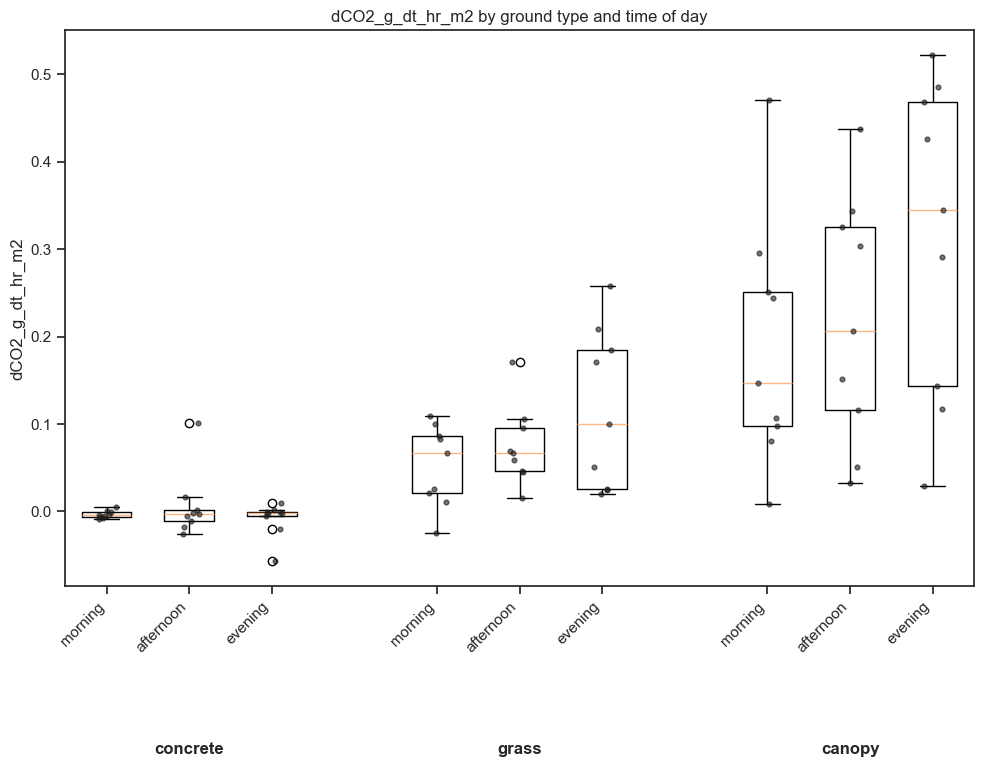

In [57]:
col = 'dCO2_g_dt_hr_m2'
ground_order = ['concrete', 'grass', 'canopy']
tod_order = ['morning', 'afternoon', 'evening']


box_data, positions = [], []
xticks, xlabels = [], []
group_centres = {}
pos = 0
for gname in ground_order:
    start = pos
    g = data[data['ground'] == gname]         
    for t in tod_order:
        vals = g.loc[g['tod'] == t, col].dropna()
        if len(vals):
            box_data.append(vals.values)
            positions.append(pos)
        xticks.append(pos)
        xlabels.append(t)
        pos += 1
    group_centres[gname] = (start + pos - 1) / 2
    pos += 1

plt.figure(figsize=(10, 8))
ax = plt.gca()
ax.boxplot(box_data, positions=positions, widths=0.6)

for vals, p in zip(box_data, positions):
    ax.scatter(np.full(len(vals), p) + np.random.uniform(-0.12, 0.12, len(vals)),
               vals, color='k', s=12, zorder=3, alpha=0.6)

plt.xticks(xticks, xlabels, rotation=45, ha='right')

for gname, c in group_centres.items():
    ax.text(c, -0.28, gname, transform=ax.get_xaxis_transform(),
            ha='center', va='top', fontweight='bold')

plt.ylabel(col)
plt.title(f'{col} by ground type and time of day')
plt.tight_layout()
plt.show()

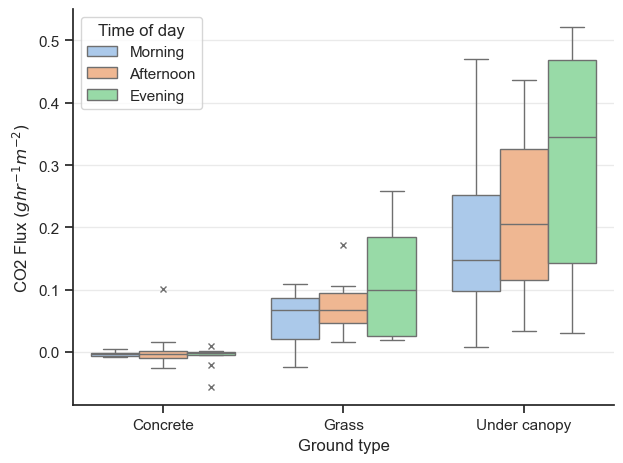

In [58]:
sns.set_theme(style="ticks", palette="pastel")

ground_order = ['concrete', 'grass', 'canopy']
tod_order = ['morning', 'afternoon', 'evening']

ax = sns.boxplot(data=data, x='ground', y='dCO2_g_dt_hr_m2', hue='tod', order=ground_order, hue_order=tod_order, flierprops=dict(marker='x', markerfacecolor='k', markersize=4))

sns.despine(top=True, right=True, left=False, bottom=False)

ax.grid(axis='y', alpha=0.4) 
ax.set_axisbelow(True)

ax.set_xlabel('Ground type')
ax.set_ylabel(r'CO2 Flux $(g hr^{-1} m^{-2})$')


ax.set_xticks(range(len(ground_order)))
ax.set_xticklabels(['Concrete', 'Grass', 'Under canopy'])


handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ['Morning', 'Afternoon', 'Evening'], title='Time of day')

plt.tight_layout()
plt.show()

In [59]:
def q1(x): return x.quantile(0.25)
def q3(x): return x.quantile(0.75)
def iqr(x): return x.quantile(0.75) - x.quantile(0.25)
def std(x): return x.std()
def sterr(x): return x.std() / np.sqrt(len(x))

In [60]:
#Flux Statistics#

col = 'dCO2_g_dt_hr_m2'


stats_flux = (data.groupby(['ground', 'tod'])[col]
             .agg(n='count', mean='mean', median='median', q1=q1, q3=q3, iqr=iqr, std=std, sterr=sterr)
             .round(4))

print('Flux statistics by ground type and time of day:')
print(stats_flux)

###############################################################################################################################
###############################################################################################################################

stats_flux_grd = (data.groupby(['ground'])[col]
             .agg(n='count', mean='mean', median='median', q1=q1, q3=q3, iqr=iqr, std=std, sterr=sterr)
             .round(4))

print('')
print('Flux statistics by ground type:')
print(stats_flux_grd)

###############################################################################################################################
###############################################################################################################################

stats_flux_tod = (data.groupby(['tod'])[col]
             .agg(n='count', mean='mean', median='median', q1=q1, q3=q3, iqr=iqr, std=std, sterr=sterr)
             .round(4))

print('')
print('Flux statistics by time of day:')
print(stats_flux_tod)

###############################################################################################################################
###############################################################################################################################

data_no_concrete = data[data['ground'] != 'concrete']
stats_flux_tod_ex_concrete = ( data_no_concrete.groupby(['tod'])[col]
             .agg(n='count', mean='mean', median='median', q1=q1, q3=q3, iqr=iqr, std=std, sterr=sterr)
             .round(4))

print('')
print('Flux statistics by time of day (ex. concrete):')
print(stats_flux_tod_ex_concrete)



Flux statistics by ground type and time of day:
                    n    mean  median      q1      q3     iqr     std   sterr
ground   tod                                                                 
canopy   afternoon  9  0.2186  0.2060  0.1157  0.3253  0.2096  0.1413  0.0471
         evening    9  0.3142  0.3449  0.1433  0.4680  0.3247  0.1798  0.0599
         morning    9  0.1892  0.1471  0.0978  0.2512  0.1534  0.1409  0.0470
concrete afternoon  9  0.0060 -0.0027 -0.0104  0.0019  0.0122  0.0377  0.0126
         evening    9 -0.0084 -0.0012 -0.0046 -0.0006  0.0040  0.0197  0.0066
         morning    9 -0.0034 -0.0038 -0.0063 -0.0012  0.0051  0.0042  0.0014
grass    afternoon  9  0.0749  0.0666  0.0464  0.0953  0.0488  0.0450  0.0150
         evening    9  0.1157  0.0996  0.0252  0.1843  0.1590  0.0914  0.0305
         morning    9  0.0531  0.0668  0.0207  0.0862  0.0655  0.0465  0.0155

Flux statistics by ground type:
           n    mean  median      q1      q3     iqr     std 

In [61]:
#Temperature Statistics#


col = 'temp'

stats_temp = (data.groupby(['ground', 'tod'])[col]
             .agg(n='count', mean='mean', median='median', q1=q1, q3=q3, iqr=iqr, std=std, sterr=sterr)
             .round(4))

print('Temperature statistics by ground type and time of day:')
print(stats_temp)

###############################################################################################################################
###############################################################################################################################

stats_temp_grd = (data.groupby(['ground'])[col]
             .agg(n='count', mean='mean', median='median', q1=q1, q3=q3, iqr=iqr, std=std, sterr=sterr)
             .round(4))

print('')
print('Temperature statistics by ground type:')
print(stats_temp_grd)

###############################################################################################################################
###############################################################################################################################

stats_temp_tod = (data.groupby(['tod'])[col]
             .agg(n='count', mean='mean', median='median', q1=q1, q3=q3, iqr=iqr, std=std, sterr=sterr)
             .round(4))

print('')
print('Temperature statistics by time of day:')
print(stats_temp_tod)

Temperature statistics by ground type and time of day:
                    n     mean  median    q1    q3  iqr     std   sterr
ground   tod                                                           
canopy   afternoon  9  10.8889    10.6  10.0  11.7  1.7  1.0362  0.3454
         evening    9   6.9333     8.1   4.1   8.3  4.2  2.2461  0.7487
         morning    9   9.0778     9.0   8.6  10.1  1.5  0.8997  0.2999
concrete afternoon  9   9.6222     9.2   8.1  11.8  3.7  1.9409  0.6470
         evening    9   6.8222     8.0   4.4   8.5  4.1  2.1632  0.7211
         morning    9   9.3000     9.2   8.0   9.9  1.9  1.2258  0.4086
grass    afternoon  9  12.2333    12.1  10.9  13.1  2.2  1.4239  0.4746
         evening    9   9.0111     8.9   8.8  10.6  1.8  2.5532  0.8511
         morning    9   8.6333     8.8   7.8   9.5  1.7  0.9069  0.3023

Temperature statistics by ground type:
           n    mean  median   q1    q3  iqr     std   sterr
ground                                              

In [ ]:
data['session'] = data['day'] + ' ' + data['tod']

sessions = [' Wednesday morning', 'Wednesday afternoon', 'Wednesday evening', 'Thursday morning', 'Thursday afternoon', 'Thursday evening', 'Friday morning', 'Friday afternoon', 'Friday evening']

data.to_parquet(data_method_dir / 'slopes.parquet')

AttributeError: module 'pandas' has no attribute 'save_parquet'

In [74]:

session_means = (data[data['ground'].isin(['grass', 'canopy'])]
                 .groupby(['session', 'ground'])['dCO2_g_dt_hr_m2'].agg(n='count', mean='mean', std=std, sterr=sterr)
                              .round(4)
                 .unstack('ground'))                  

sm = (data[data['ground'].isin(['grass', 'canopy'])]
                 .groupby(['session', 'ground'])['dCO2_g_dt_hr_m2'].mean()
                 .unstack('ground'))   

session_means['diff'] = sm['canopy'] - sm['grass']


print('flux means by session (no concrete):')
print(session_means)

flux means by session (no concrete):
                         n          mean             std           sterr  \
ground              canopy grass  canopy   grass  canopy   grass  canopy   
session                                                                    
Friday afternoon         3     3  0.3688  0.0603  0.0598  0.0453  0.0345   
Friday evening           3     3  0.4448  0.1598  0.0906  0.0555  0.0523   
Friday morning           3     3  0.1281  0.0231  0.1495  0.0549  0.0863   
Thursday afternoon       3     3  0.1568  0.0694  0.1309  0.0245  0.0756   
Thursday evening         3     3  0.1547  0.0316  0.1312  0.0166  0.0757   
Thursday morning         3     3  0.2732  0.0874  0.1874  0.0213  0.1082   
Wednesday afternoon      3     3  0.1301  0.0950  0.0886  0.0668  0.0512   
Wednesday evening        3     3  0.3429  0.1558  0.1973  0.1189  0.1139   
Wednesday morning        3     3  0.1663  0.0488  0.0708  0.0449  0.0409   

                                 diff  
ground    

In [ ]:
tclass =[]
for t in data['temp']:
    if t < 5:
        tclass.append('cold')
    elif t > 5 and t < 10:
        tclass.append('moderate')
    else:
        tclass.append('hot')

data['temp_class'] = tclass
data.to_parquet(data_method_dir / 'slopes.parquet')

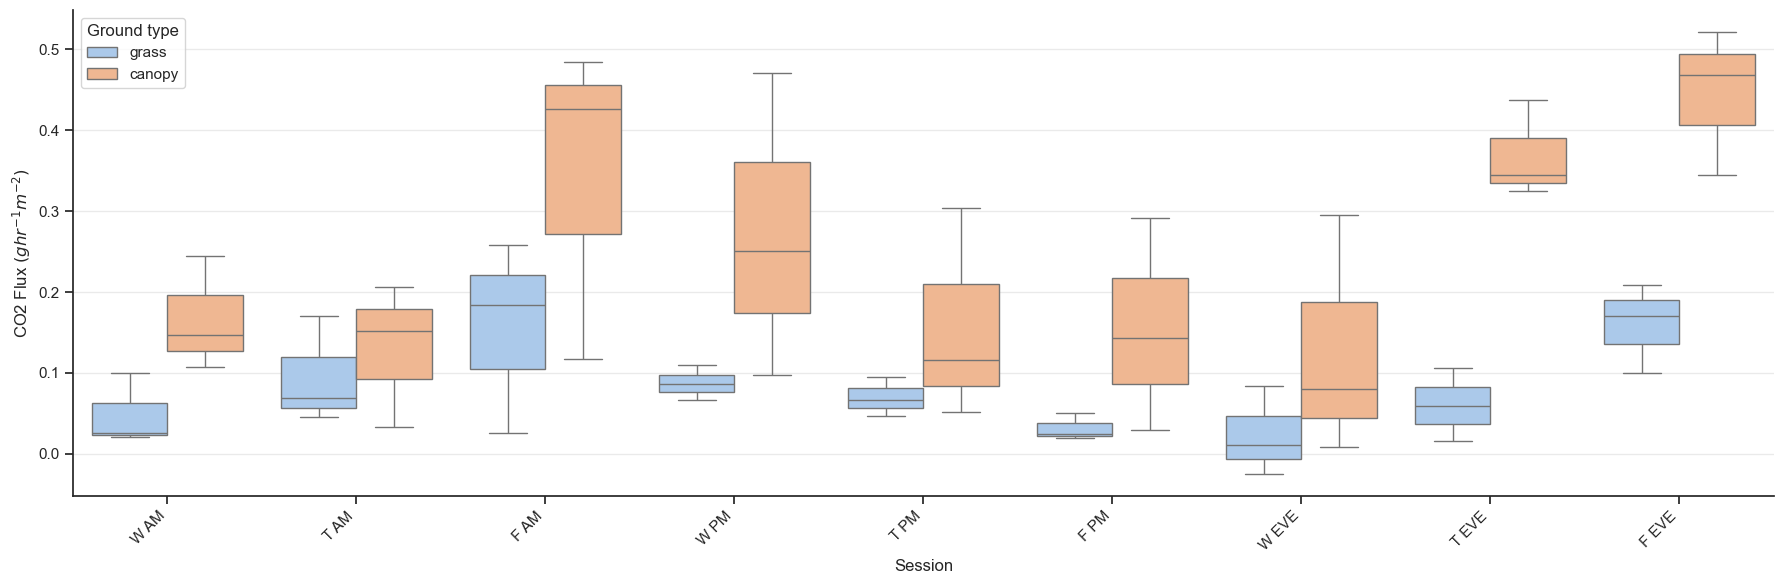

In [ ]:

sns.set_theme(style="ticks", palette="pastel")

ground_order = ['grass', 'canopy']
sesh_order = ['W AM', 'T AM', 'F AM', 'W PM', 'T PM', 'F PM', 'W EVE', 'T EVE', 'F EVE']
temp_order = ['cold', 'moderate', 'hot']
tod_order = ['morning', 'afternoon', 'evening']

no_concrete = data[data['ground'] != 'concrete'].copy()

plt.figure(figsize=(18, 6))
ax = sns.boxplot(data=no_concrete, x='session', y='dCO2_g_dt_hr_m2', hue='ground',  hue_order=ground_order, flierprops=dict(marker='x', markerfacecolor='k', markersize=4))

sns.despine(top=True, right=True, left=False, bottom=False)


ax.grid(axis = 'y',alpha=0.4) 
ax.set_axisbelow(True)

ax.set_xlabel('Session')
ax.set_ylabel(r'CO2 Flux $(g hr^{-1} m^{-2})$')



ax.set_xticks(range(len(sesh_order)))
ax.set_xticklabels(sesh_order, rotation=45, ha='right')


handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ground_order, title='Ground type')

plt.tight_layout()
plt.show()


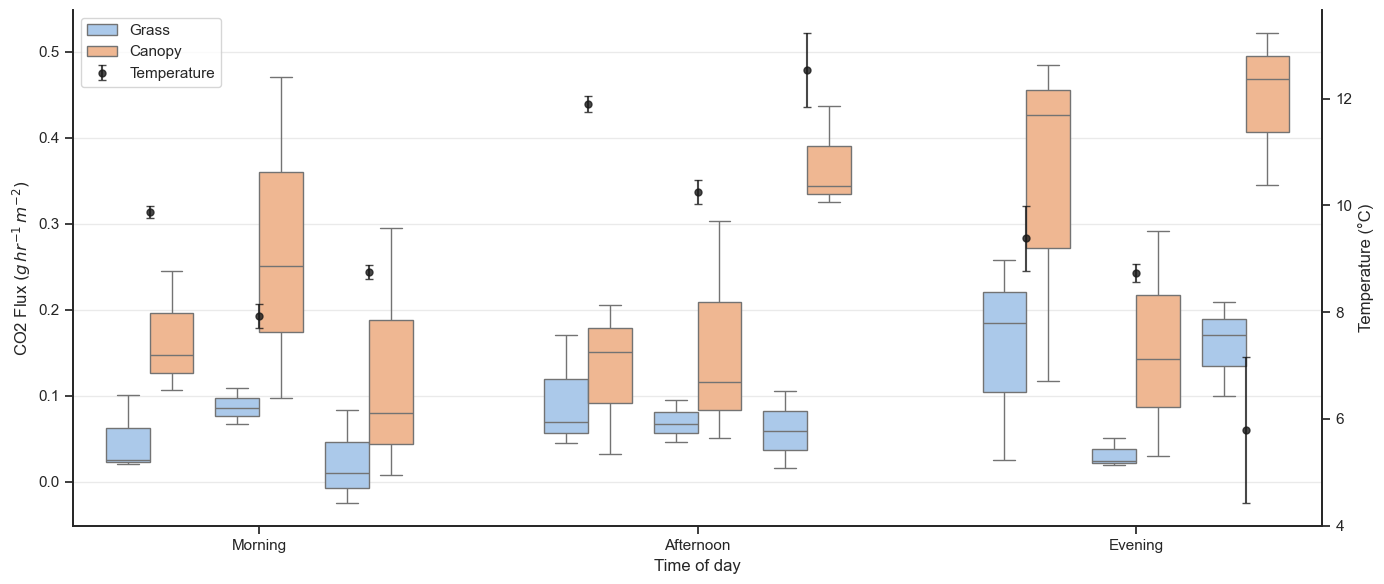

In [128]:
sns.set_theme(style="ticks", palette="pastel")

ground_order = ['grass', 'canopy']
sesh_order = ['Wednesday morning', 'Thursday morning', 'Friday morning', 'Wednesday afternoon', 'Thursday afternoon', 'Friday afternoon', 'Wednesday evening', 'Thursday evening', 'Friday evening']

# x position for each session: 3 per block, one empty slot between blocks -> 0,1,2, 4,5,6, 8,9,10
xpos = {s: i + i // 3 for i, s in enumerate(sesh_order)}
block_centres = [1, 5, 9]
tod_labels = ['morning', 'afternoon', 'evening']

no_concrete = data[data['ground'] != 'concrete'].copy()
no_concrete['xpos'] = no_concrete['session'].map(xpos)

# mean temperature and standard error for each session
temp_stats = (no_concrete.groupby('session')['temp']
              .agg(mean='mean', sem='sem').reset_index())
temp_stats['xpos'] = temp_stats['session'].map(xpos)

fig, ax = plt.subplots(figsize=(14, 6))

sns.boxplot(data=no_concrete, x='xpos', y='dCO2_g_dt_hr_m2',
            hue='ground', hue_order=ground_order,
            native_scale=True, width=0.8,
            flierprops=dict(marker='x', markerfacecolor='k', markersize=4), ax=ax)

ax.grid(axis='y', alpha=0.4)
ax.set_axisbelow(True)
ax.set_xlim(-0.7, 10.7)

# label only the time-of-day blocks
ax.set_xticks(block_centres)
ax.set_xticklabels(['Morning', 'Afternoon', 'Evening'])
ax.set_xlabel('Time of day')
ax.set_ylabel(r'CO2 Flux $(g\,hr^{-1}\,m^{-2})$')

# second axis: mean temp ± SE for each session
ax2 = ax.twinx()
temp_h = ax2.errorbar(temp_stats['xpos'], temp_stats['mean'], yerr=temp_stats['sem'],
                      fmt='o', color='k', capsize=3, markersize=5, label='Temperature', alpha=0.8)
ax2.set_ylabel('Temperature (°C)')
ax2.spines['top'].set_visible(False)
ax.spines['top'].set_visible(False)

# single combined legend, drawn on the top axis
box_handles, _ = ax.get_legend_handles_labels()
ax.get_legend().remove()
ax2.legend(box_handles + [temp_h], ['Grass', 'Canopy'] + ['Temperature'],
            loc='upper left')

plt.tight_layout()


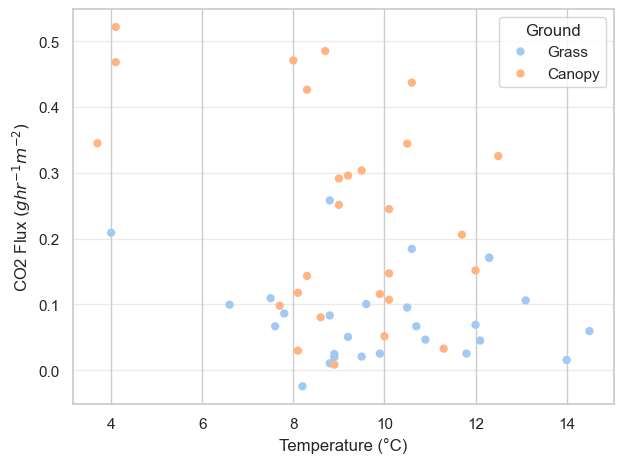

In [127]:
sns.set_theme(style="whitegrid", palette="pastel")


no_concrete = data[data['ground'] != 'concrete'].copy()


ax = sns.scatterplot(x="temp", y='dCO2_g_dt_hr_m2',
                hue="ground", 
                hue_order=ground_order,
                sizes=(1, 8), linewidth=0,
                data=no_concrete)



ax.grid(axis='y', alpha=0.4) 
ax.set_axisbelow(True)

ax.set_xlabel('Temperature (°C)')
ax.set_ylabel(r'CO2 Flux $(g hr^{-1} m^{-2})$')


handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ['Grass', 'Canopy'], title='Ground')

plt.tight_layout()
plt.show()

### Claude's Idea:

In [112]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from scipy import stats

sns.set_theme(style="ticks", palette="pastel")

col = 'dCO2_g_dt_hr_m2'
flux_label = r'CO2 Flux $(g\,hr^{-1}\,m^{-2})$'
ground_order = ['grass', 'canopy']
tod_order = ['morning', 'afternoon', 'evening']
day_order = ['Wednesday', 'Thursday', 'Friday']     # must match the values in your 'day' column

no_concrete = data[data['ground'] != 'concrete'].copy()
no_concrete['temp'] = pd.to_numeric(no_concrete['temp'])

C:\Users\Ealish\AppData\Local\Temp\ipykernel_5152\2572254754.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([t.capitalize() for t in tod_order])


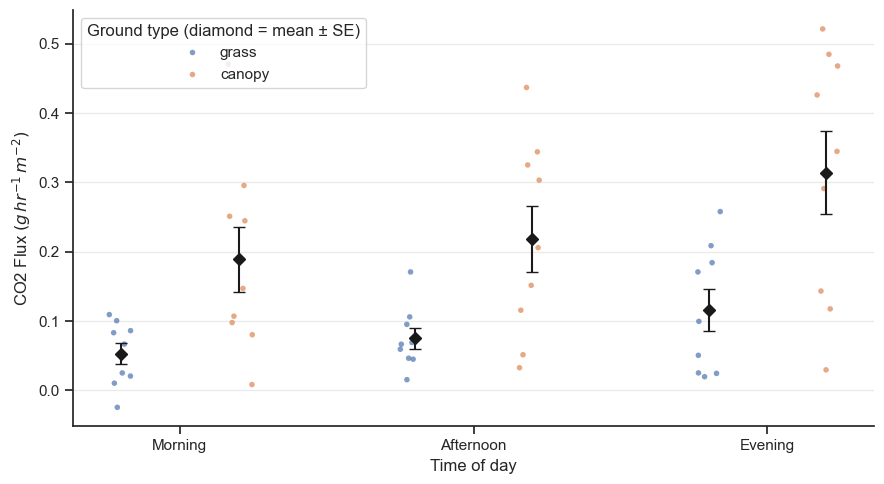

In [114]:
fig, ax = plt.subplots(figsize=(9, 5))

sns.stripplot(data=no_concrete, x='tod', y=col, hue='ground',
              order=tod_order, hue_order=ground_order,
              dodge=True, size=4, alpha=0.7, palette='deep', ax=ax)

# mean ± standard error, placed over the dodged points
summ = no_concrete.groupby(['tod', 'ground'])[col].agg(['mean', 'sem']).reset_index()
offset = {'grass': -0.2, 'canopy': 0.2}
for _, r in summ.iterrows():
    xi = tod_order.index(r['tod']) + offset[r['ground']]
    ax.errorbar(xi, r['mean'], yerr=r['sem'], fmt='D', color='k',
                capsize=4, markersize=6, zorder=5)

ax.set_xticklabels([t.capitalize() for t in tod_order])
ax.set_xlabel('Time of day')
ax.set_ylabel(flux_label)
ax.grid(axis='y', alpha=0.4)
ax.set_axisbelow(True)
ax.legend(title='Ground type (diamond = mean ± SE)')
sns.despine()
plt.tight_layout()
plt.show()